# Étape 2 : moteur de prédiction du rendement (modélisation + MLflow)

**Objectif** : à partir de la culture, de la pluie annuelle et de la température moyenne, prédire le rendement (t/ha), puis en déduire un classement des cultures pour `/recommend`.

**Plan**
1. Chargement et split (par pays)
2. Briques communes (pipeline, métriques, logging MLflow)
3. Baselines et comparaison de modèles
4. Optimisation des hyperparamètres du meilleur (RandomizedSearch, runs enfants)
5. Évaluation finale sur le jeu de test + importance des variables
6. Pourquoi on a écarté `area`, `pesticides`, `year` (ablation)
7. Sauvegarde du modèle + démo de recommandation

**Choix assumés** (voir étape 1) : variables limitées à `item`, `rain_mm`, `temp_c` et `pest_kg_ha` (pesticides en kg de matière active par ha de terres cultivées, FAOSTAT) car ce sont les seules que l'agriculteur peut renseigner. Cible entraînée en `log1p(yield_t_ha)`, métriques toutes reportées en **t/ha**.

In [ ]:
from pathlib import Path
import warnings
import numpy as np, pandas as pd, yaml, joblib
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, mlflow, mlflow.sklearn
from mlflow.models import infer_signature
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, RandomizedSearchCV,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
try:
    from lightgbm import LGBMRegressor
except ImportError:
    LGBMRegressor = None

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

# Racine du projet = dossier qui contient config.yaml (marche depuis la racine ou depuis notebooks/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text())
SEED = CFG["seed"]
np.random.seed(SEED)
print("Racine :", ROOT, "| seed :", SEED, "| sklearn", sklearn.__version__, "| mlflow", mlflow.__version__)

Racine : c:\Users\jacob\Desktop\OpenClassRoom\Projet-12-LLM-Reco-Agriculture-Optimisée-Data\P12 | seed : 42 | sklearn 1.7.2 | mlflow 3.13.0


In [2]:
# ---- Paramètres de l'expérience ----
TARGET = "yield_t_ha"
BASE = ["item", "rain_mm", "temp_c"]
FEATS = BASE + ["pest_kg_ha"]               # variables retenues pour le modèle final
CAT = ["item", "area"]                     # colonnes catégorielles (OneHot)
TEST_SIZE, CV_FOLDS, N_ITER = 0.2, 5, 20

TRACKING_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"
mlflow.set_tracking_uri(TRACKING_URI)
EXP_MODELS = "yield-model-selection"
EXP_ABLATION = "yield-ablation-variables"

def set_exp(name):
    # artefacts stockés dans <racine>/mlruns/<expérience>, quel que soit le dossier d'exécution
    if mlflow.get_experiment_by_name(name) is None:
        mlflow.create_experiment(name, artifact_location=(ROOT / "mlruns" / name).as_uri())
    mlflow.set_experiment(name)

## 1. Chargement et split

In [3]:
df = pd.read_csv(ROOT / CFG["paths"]["clean"])

# Garde-fous
missing = [c for c in FEATS if c not in df.columns]
assert not missing, f"colonnes absentes du CSV : {missing} (ajoute pest_kg_ha au consolidé, voir étape 1)"
assert len(df) == CFG["expected_rows"], f"{len(df)} lignes au lieu de {CFG['expected_rows']}"
assert not df.isna().any().any(), "valeurs manquantes"
assert not df.duplicated(CFG["dedup_keys"]).any(), "doublons"
print(df.shape); df.head()

(13130, 11)


,area,item,item_fr,year,rain_mm,pesticides_t,log_pest,pest_kg_ha,temp_c,yield_t_ha,log_yield
0,Albania,Maize,Maïs,1990,1485.0,121.0,4.804021,0.17,16.37,3.6613,1.539294
1,Albania,Maize,Maïs,1991,1485.0,121.0,4.804021,0.17,15.36,2.9068,1.362719
2,Albania,Maize,Maïs,1992,1485.0,121.0,4.804021,0.17,16.06,2.4876,1.249214
3,Albania,Maize,Maïs,1993,1485.0,121.0,4.804021,0.17,16.05,2.4185,1.229202
4,Albania,Maize,Maïs,1994,1485.0,201.0,5.308268,0.29,16.96,2.5848,1.276703


**Split par pays, pas aléatoire.** Dans ce jeu, `rain_mm` est constante pour un pays donné (une seule valeur par pays) : elle joue le rôle d'un identifiant de pays. Avec un split aléatoire, le modèle verrait le même pays en train et en test et "reconnaîtrait" le pays via la pluie, ce qui gonfle le score. On met donc des **pays entiers** en test (et on utilise `GroupKFold` par pays pour la validation croisée). La section 6 chiffre cet effet.

In [4]:
assert (df.groupby("area")["rain_mm"].nunique() == 1).all()   # vérifie l'affirmation ci-dessus

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df["area"]))
train, test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)

assert set(train.area).isdisjoint(test.area)
print(f"train : {len(train)} lignes, {train.area.nunique()} pays | test : {len(test)} lignes, {test.area.nunique()} pays")
print("pays en test :", sorted(test.area.unique()))

train : 10978 lignes, 80 pays | test : 2152 lignes, 21 pays
pays en test : ['Albania', 'Armenia', 'Bangladesh', 'Belgium', 'Cameroon', 'Colombia', 'Estonia', 'Finland', 'Germany', 'Haiti', 'Iraq', 'Ireland', 'Lithuania', 'Namibia', 'Nepal', 'Poland', 'Portugal', 'Qatar', 'South Africa', 'Tunisia', 'United Kingdom']


## 2. Briques communes : pipeline, métriques, logging MLflow

In [5]:
MODELS = {
    "dummy_mean":        lambda: DummyRegressor(strategy="mean"),
    "item_mean":         lambda: LinearRegression(),   # = rendement moyen par culture
    "ridge":             lambda: Ridge(alpha=1.0),
    "ridge_poly2":       lambda: Ridge(alpha=1.0),
    "random_forest":     lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=1),
    "gradient_boosting": lambda: GradientBoostingRegressor(random_state=SEED),
}
if XGBRegressor is not None:
    MODELS["xgboost"] = lambda: XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                             colsample_bytree=0.8, random_state=SEED, n_jobs=1, verbosity=0)
else:
    print("xgboost non installé : modèle ignoré (pip install xgboost)")
if LGBMRegressor is not None:
    MODELS["lightgbm"] = lambda: LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8,
                                               subsample_freq=1, colsample_bytree=0.8, min_child_samples=20,
                                               random_state=SEED, n_jobs=1, verbose=-1)
else:
    print("lightgbm non installé : modèle ignoré (pip install lightgbm)")

def make_pipe(name, feats):
    """Pipeline complet (preprocessing + modèle). Cible entraînée en log1p, prédictions rendues en t/ha."""
    cat = [c for c in feats if c in CAT]
    num = [c for c in feats if c not in CAT]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("num", StandardScaler(), num),
    ])
    steps = [("prep", prep)]
    if name == "ridge_poly2":   # interactions culture x climat et termes quadratiques
        steps.append(("poly", PolynomialFeatures(2, include_bias=False)))
    steps.append(("model", MODELS[name]()))
    return TransformedTargetRegressor(Pipeline(steps), func=np.log1p, inverse_func=np.expm1, check_inverse=False)

SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

def reg_metrics(y, p, prefix):
    return {f"{prefix}_rmse": float(np.sqrt(mean_squared_error(y, p))),
            f"{prefix}_mae": float(mean_absolute_error(y, p)),
            f"{prefix}_r2": float(r2_score(y, p))}

# Moyenne de rendement par culture (sur le train uniquement) = la "norme" de chaque culture
ITEM_MEAN = train.groupby("item")[TARGET].mean()

def reco_top1(pred, data):
    """Taux de bonne recommandation : pour chaque (pays, année) du test, la culture que le modèle classe
    1re (écart prédit vs norme de la culture) est-elle vraiment la meilleure ? Comparé au hasard (1/nb cultures)."""
    d = data[["area", "year", "item", TARGET]].copy()
    d["real_rel"] = d[TARGET] / d["item"].map(ITEM_MEAN)
    d["pred_rel"] = pred / d["item"].map(ITEM_MEAN)
    hits, rnd = [], []
    for _, g in d.groupby(["area", "year"]):
        if len(g) < 3:
            continue
        hits.append(g["real_rel"].idxmax() == g["pred_rel"].idxmax())
        rnd.append(1 / len(g))
    return float(np.mean(hits)), float(np.mean(rnd))

RESULTS, FITTED = [], {}

def fit_eval_log(run_name, model_name, feats, family, note):
    """CV groupée sur le train + fit complet + métriques train/test + gap, le tout loggé dans MLflow."""
    pipe = make_pipe(model_name, feats)
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({"family": family, "stage": "model_selection", "mlflow.note.content": note})
        mlflow.log_params({"features": ",".join(feats), "split": "GroupShuffleSplit(area)",
                           "cv": f"GroupKFold({CV_FOLDS})", "seed": SEED, "target": "log1p(yield_t_ha)"})
        mlflow.log_params({f"model__{k}": v for k, v in pipe.regressor.named_steps["model"].get_params().items()})

        cv = cross_validate(pipe, train[feats], train[TARGET], groups=train["area"], cv=GroupKFold(CV_FOLDS),
                            scoring=SCORING, n_jobs=-1)
        m = {"cv_rmse": -cv["test_rmse"].mean(), "cv_rmse_std": cv["test_rmse"].std(),
             "cv_mae": -cv["test_mae"].mean(), "cv_r2": cv["test_r2"].mean()}

        pipe.fit(train[feats], train[TARGET])
        p_tr, p_te = pipe.predict(train[feats]), pipe.predict(test[feats])
        m |= reg_metrics(train[TARGET], p_tr, "train") | reg_metrics(test[TARGET], p_te, "test")
        m["gap_rmse"] = m["test_rmse"] - m["train_rmse"]      # > 0 : le modèle fait pire sur des pays inconnus
        m["gap_r2"] = m["train_r2"] - m["test_r2"]
        m["reco_top1"], m["reco_top1_random"] = reco_top1(p_te, test)
        mlflow.log_metrics(m)
    FITTED[run_name] = pipe
    RESULTS.append({"run": run_name, "model": model_name, **m})
    return m

## 3. Baselines et comparaison de modèles

In [6]:
set_exp(EXP_MODELS)

fit_eval_log("baseline_dummy_mean", "dummy_mean", ["item"], "baseline",
             "Baseline minimale : prédit toujours la moyenne globale. Tout modèle doit faire mieux.")
fit_eval_log("baseline_item_mean", "item_mean", ["item"], "baseline",
             "Baseline métier : rendement moyen par culture, sans pluie ni température. Mesure ce que le climat apporte en plus de la culture.")
fit_eval_log("ridge", "ridge", FEATS, "linear",
             "Linéaire régularisé : référence interprétable, sans interactions.")
fit_eval_log("ridge_poly2", "ridge_poly2", FEATS, "linear",
             "Ridge + interactions culture x climat et termes quadratiques.")
fit_eval_log("random_forest", "random_forest", FEATS, "tree_ensemble",
             "RandomForest, hyperparamètres modérés (200 arbres, min_samples_leaf=5).")
fit_eval_log("gradient_boosting", "gradient_boosting", FEATS, "tree_ensemble",
             "GradientBoosting, hyperparamètres par défaut.")
if "xgboost" in MODELS:
    fit_eval_log("xgboost", "xgboost", FEATS, "tree_ensemble",
                 "XGBoost, hyperparamètres modérés (300 arbres, learning_rate=0.05, max_depth=4, subsample=0.8).")
if "lightgbm" in MODELS:
    fit_eval_log("lightgbm", "lightgbm", FEATS, "tree_ensemble",
                 "LightGBM, hyperparamètres modérés (300 arbres, learning_rate=0.05, 15 feuilles, subsample=0.8).")

res = pd.DataFrame(RESULTS).set_index("run")
cols = ["cv_rmse", "cv_mae", "cv_r2", "test_rmse", "test_mae", "test_r2", "gap_rmse", "reco_top1", "reco_top1_random"]
res[cols].round(3)

2026/10/30 18:03:14 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/30 18:03:14 INFO mlflow.store.db.utils: Updating database tables
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,cv_rmse,cv_mae,cv_r2,test_rmse,test_mae,test_r2,gap_rmse,reco_top1,reco_top1_random
run,,,,,,,,,
baseline_dummy_mean,8.113,5.212,-0.110,8.965,5.421,-0.109,0.779,0.066,0.227
baseline_item_mean,5.545,3.381,0.483,5.881,3.162,0.523,0.367,0.151,0.227
ridge,7.126,3.519,-0.066,6.145,3.233,0.479,1.125,0.149,0.227
ridge_poly2,5.103,3.039,0.537,40.721,7.019,-21.875,36.204,0.334,0.227
random_forest,5.367,3.208,0.513,5.040,2.947,0.650,3.356,0.382,0.227
gradient_boosting,4.945,2.947,0.583,4.214,2.511,0.755,0.416,0.363,0.227
xgboost,4.921,2.968,0.577,4.613,2.748,0.706,1.757,0.438,0.227
lightgbm,4.994,3.015,0.567,4.477,2.626,0.724,1.766,0.493,0.227


Lecture : la **sélection** se fait sur `cv_rmse` (validation croisée sur le train, pays séparés). Les colonnes `test_*` ne servent qu'à vérifier la généralisation. `gap_rmse` = écart test moins train (overfit). `reco_top1` = part des (pays, année) où le modèle place bien la meilleure culture en tête, à comparer à `reco_top1_random` (hasard).

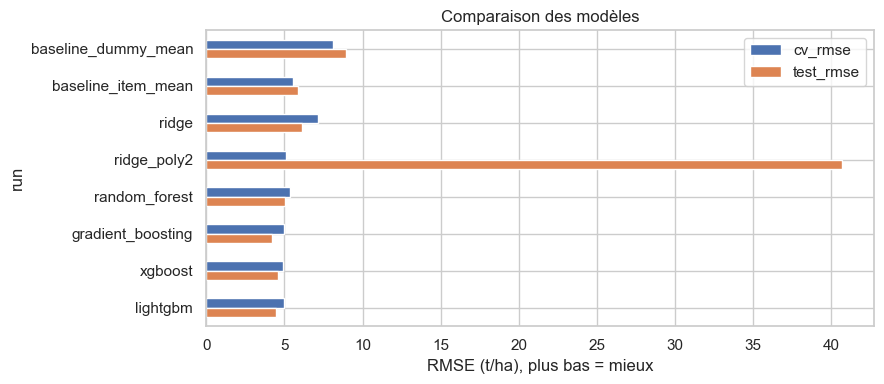

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
res[["cv_rmse", "test_rmse"]].plot.barh(ax=ax)
ax.set_xlabel("RMSE (t/ha), plus bas = mieux"); ax.set_title("Comparaison des modèles"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

**À toi (5 min, à l'écrit)** : pourquoi le meilleur modèle gagne-t-il ? Que montre l'écart entre `baseline_item_mean` et les autres sur ce que pluie + température apportent ? Que dit `gap_rmse` des modèles à arbres ?

## 4. Optimisation des hyperparamètres

**Quels modèles optimiser ?** Le Ridge simple est une bonne référence interprétable, mais il applique **le même effet climat à toutes les cultures** : il ne peut pas classer les cultures différemment selon le climat, ce qui est justement le but de `/recommend`. On optimise donc les modèles à arbres, capables de capter des interactions culture x climat : `random_forest`, `gradient_boosting`, et `xgboost` / `lightgbm` s'ils sont installés. On retient celui qui a le meilleur `cv_rmse`.

`ridge_poly2` reste dans la comparaison de la section 3 mais n'est pas optimisé : ses termes quadratiques extrapolent mal sur les valeurs extrêmes (certains pays dépassent 30 kg/ha de pesticides), regarde son `test_r2` dans le tableau.

Plages de recherche : peu de variables (4) et peu de signal, donc on pousse la **régularisation** (`min_samples_leaf` / `min_child_weight` / `min_child_samples`, profondeur ou nombre de feuilles limités, `learning_rate` faible avec plus d'arbres, `subsample` < 1, pénalité L2) pour éviter que le modèle mémorise des pays.

In [8]:
p = "regressor__model__"
SEARCH_SPACES = {
    "random_forest": {p + "n_estimators": [100, 200, 300, 500],
                      p + "max_depth": [4, 6, 8, 12, 16, None],
                      p + "min_samples_leaf": [1, 3, 5, 10, 20],
                      p + "max_features": [0.5, 0.75, 1.0]},
    "gradient_boosting": {p + "n_estimators": [100, 200, 300, 500],
                          p + "learning_rate": loguniform(0.02, 0.3),
                          p + "max_depth": [2, 3, 4, 5, 6],
                          p + "subsample": [0.6, 0.8, 1.0],
                          p + "min_samples_leaf": [1, 5, 10, 20]},
}
if "xgboost" in MODELS:
    SEARCH_SPACES["xgboost"] = {p + "n_estimators": [100, 200, 300, 500],
                                p + "learning_rate": loguniform(0.02, 0.3),
                                p + "max_depth": [2, 3, 4, 5, 6],
                                p + "subsample": [0.6, 0.8, 1.0],
                                p + "colsample_bytree": [0.6, 0.8, 1.0],
                                p + "min_child_weight": [1, 5, 10, 20],
                                p + "reg_lambda": loguniform(0.1, 30)}
if "lightgbm" in MODELS:
    SEARCH_SPACES["lightgbm"] = {p + "n_estimators": [100, 200, 300, 500],
                                 p + "learning_rate": loguniform(0.02, 0.3),
                                 p + "num_leaves": [7, 15, 31, 63],
                                 p + "min_child_samples": [10, 20, 50, 100],
                                 p + "subsample": [0.6, 0.8, 1.0],
                                 p + "colsample_bytree": [0.6, 0.8, 1.0],
                                 p + "reg_lambda": loguniform(0.1, 30)}

TUNED = {}
for name, space in SEARCH_SPACES.items():
    srch = RandomizedSearchCV(
        make_pipe(name, FEATS), space, n_iter=N_ITER, scoring=SCORING, refit="rmse",
        cv=GroupKFold(CV_FOLDS), n_jobs=-1, random_state=SEED, return_train_score=True)

    with mlflow.start_run(run_name=f"tuning_{name}"):
        mlflow.set_tags({"stage": "tuning", "family": "search",
                         "mlflow.note.content": f"RandomizedSearch ({N_ITER} candidats, GroupKFold {CV_FOLDS} par pays) sur {name}. Un run enfant par candidat."})
        mlflow.log_params({"model": name, "n_iter": N_ITER, "cv": f"GroupKFold({CV_FOLDS})", "seed": SEED, "features": ",".join(FEATS)})
        srch.fit(train[FEATS], train[TARGET], groups=train["area"])

        cvr = srch.cv_results_
        for i, params in enumerate(cvr["params"]):
            with mlflow.start_run(run_name=f"{name}_candidat_{i:02d}", nested=True):
                mlflow.log_params({k.replace(p, ""): v for k, v in params.items()})
                mlflow.log_metrics({"cv_rmse": -cvr["mean_test_rmse"][i], "cv_rmse_std": cvr["std_test_rmse"][i],
                                    "cv_mae": -cvr["mean_test_mae"][i], "cv_r2": cvr["mean_test_r2"][i],
                                    "cv_train_rmse": -cvr["mean_train_rmse"][i]})
                mlflow.set_tag("rank_cv_rmse", int(cvr["rank_test_rmse"][i]))

        est, k = srch.best_estimator_, srch.best_index_       # déjà ré-entraîné sur tout le train
        mlflow.log_params({f"best__{kk.replace(p, '')}": v for kk, v in srch.best_params_.items()})
        p_tr, p_te = est.predict(train[FEATS]), est.predict(test[FEATS])
        m = {"cv_rmse": -cvr["mean_test_rmse"][k], "cv_rmse_std": cvr["std_test_rmse"][k],
             "cv_mae": -cvr["mean_test_mae"][k], "cv_r2": cvr["mean_test_r2"][k]}
        m |= reg_metrics(train[TARGET], p_tr, "train") | reg_metrics(test[TARGET], p_te, "test")
        m["gap_rmse"] = m["test_rmse"] - m["train_rmse"]; m["gap_r2"] = m["train_r2"] - m["test_r2"]
        m["reco_top1"], m["reco_top1_random"] = reco_top1(p_te, test)
        mlflow.log_metrics(m)

    TUNED[name] = {"search": srch, "est": est, "metrics": m}
    RESULTS.append({"run": f"tuned_{name}", "model": name, **m})
    print(f"{name:18s} cv_rmse {m['cv_rmse']:.3f} | test_rmse {m['test_rmse']:.3f} | meilleurs params :",
          {kk.replace(p, ""): (round(v, 4) if isinstance(v, float) else v) for kk, v in srch.best_params_.items()})

# Modèle retenu = meilleur cv_rmse parmi les modèles optimisés
best_name = min(TUNED, key=lambda n: TUNED[n]["metrics"]["cv_rmse"])
search, best_est, mt = TUNED[best_name]["search"], TUNED[best_name]["est"], TUNED[best_name]["metrics"]
print("\n=> Modèle retenu :", best_name)

# Quels hyperparamètres comptent ? (top 10 candidats du modèle retenu)
cvr = search.cv_results_
top = pd.DataFrame(cvr["params"]).rename(columns=lambda c: c.replace(p, ""))
top["cv_rmse"] = -cvr["mean_test_rmse"]; top["cv_train_rmse"] = -cvr["mean_train_rmse"]
top.sort_values("cv_rmse").head(10).round(3)

random_forest      cv_rmse 4.873 | test_rmse 4.351 | meilleurs params : {'n_estimators': 500, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 8}
gradient_boosting  cv_rmse 4.791 | test_rmse 4.158 | meilleurs params : {'learning_rate': np.float64(0.1786), 'max_depth': 2, 'min_samples_leaf': 5, 'n_estimators': 100, 'subsample': 0.8}
xgboost            cv_rmse 4.731 | test_rmse 4.216 | meilleurs params : {'colsample_bytree': 0.8, 'learning_rate': np.float64(0.034), 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 500, 'reg_lambda': np.float64(12.3598), 'subsample': 0.6}


c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


lightgbm           cv_rmse 4.720 | test_rmse 4.285 | meilleurs params : {'colsample_bytree': 1.0, 'learning_rate': np.float64(0.0254), 'min_child_samples': 50, 'n_estimators': 500, 'num_leaves': 7, 'reg_lambda': np.float64(24.0403), 'subsample': 0.6}

=> Modèle retenu : lightgbm


,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,subsample,cv_rmse,cv_train_rmse
11,1.0,0.025,50,500,7,24.040,0.6,4.720,3.537
2,0.8,0.023,100,500,15,0.336,0.6,4.799,3.059
6,1.0,0.205,50,100,7,0.145,0.6,4.812,3.119
16,0.6,0.024,50,200,63,4.462,0.8,4.893,2.746
17,1.0,0.091,50,100,31,5.845,0.6,4.910,2.551
12,0.6,0.042,10,500,15,24.607,0.6,4.910,2.663
13,0.6,0.045,10,100,7,27.838,0.6,4.936,4.513
7,0.8,0.179,10,200,7,0.373,1.0,4.954,2.645
19,1.0,0.027,100,100,31,0.120,1.0,4.968,3.783
3,0.6,0.046,20,100,63,0.114,1.0,4.976,2.467


**À toi** : quels hyperparamètres semblent décisifs (compare les meilleurs et les pires candidats) ? L'optimisation change-t-elle beaucoup par rapport au modèle avant tuning ?

## 5. Évaluation finale (jeu de test) et importance des variables

In [9]:
final = pd.DataFrame(RESULTS).set_index("run")
final[cols].round(3)

,cv_rmse,cv_mae,cv_r2,test_rmse,test_mae,test_r2,gap_rmse,reco_top1,reco_top1_random
run,,,,,,,,,
baseline_dummy_mean,8.113,5.212,-0.110,8.965,5.421,-0.109,0.779,0.066,0.227
baseline_item_mean,5.545,3.381,0.483,5.881,3.162,0.523,0.367,0.151,0.227
ridge,7.126,3.519,-0.066,6.145,3.233,0.479,1.125,0.149,0.227
ridge_poly2,5.103,3.039,0.537,40.721,7.019,-21.875,36.204,0.334,0.227
random_forest,5.367,3.208,0.513,5.040,2.947,0.650,3.356,0.382,0.227
gradient_boosting,4.945,2.947,0.583,4.214,2.511,0.755,0.416,0.363,0.227
xgboost,4.921,2.968,0.577,4.613,2.748,0.706,1.757,0.438,0.227
lightgbm,4.994,3.015,0.567,4.477,2.626,0.724,1.766,0.493,0.227
tuned_random_forest,4.873,2.943,0.597,4.351,2.545,0.739,0.786,0.252,0.227


c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


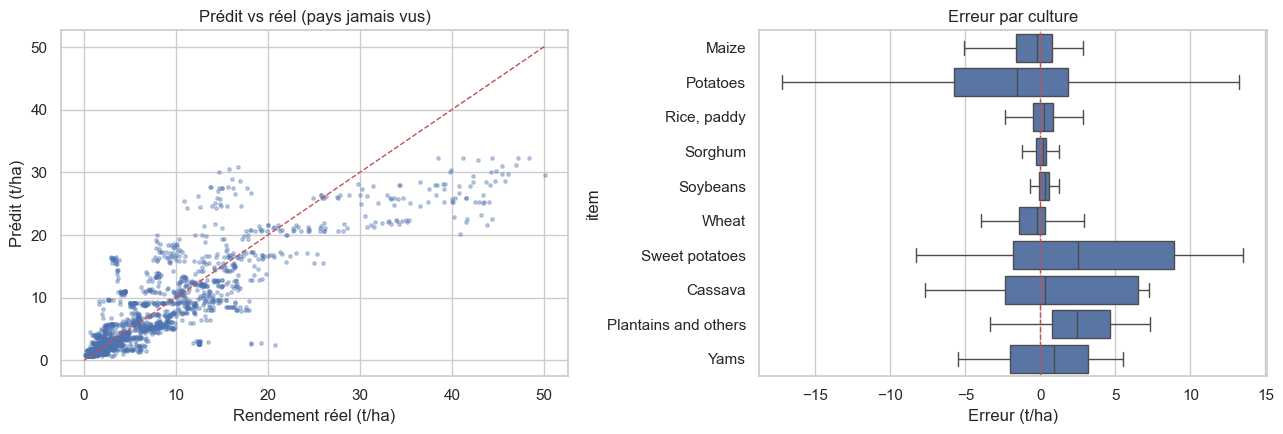

In [10]:
pred_te = best_est.predict(test[FEATS])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(test[TARGET], pred_te, s=6, alpha=.35)
lim = [0, max(test[TARGET].max(), pred_te.max())]
axes[0].plot(lim, lim, "r--", lw=1); axes[0].set_xlabel("Rendement réel (t/ha)"); axes[0].set_ylabel("Prédit (t/ha)")
axes[0].set_title("Prédit vs réel (pays jamais vus)")

err = pd.DataFrame({"item": test["item"], "erreur": pred_te - test[TARGET]})
sns.boxplot(data=err, y="item", x="erreur", ax=axes[1], showfliers=False)
axes[1].axvline(0, color="r", lw=1, ls="--"); axes[1].set_xlabel("Erreur (t/ha)"); axes[1].set_title("Erreur par culture")
plt.tight_layout(); fig_eval = fig; plt.show()

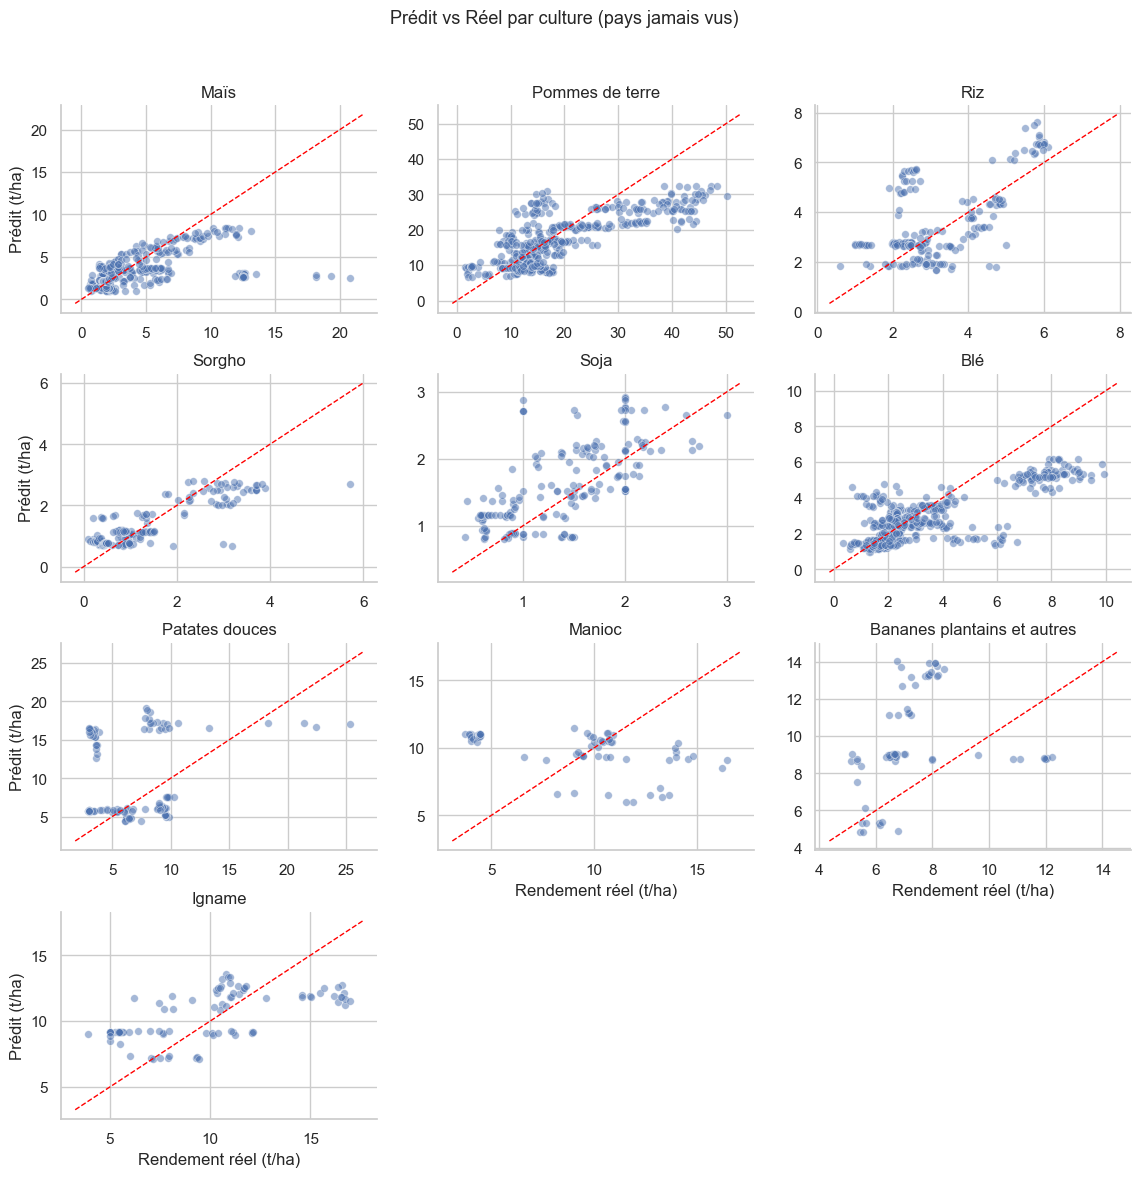

In [18]:
# --- AJOUT : Scatter plot par culture (Corrigé & points plus gros) ---
item_col = "item_fr" if "item_fr" in test.columns else "item"

df_viz = test.copy()
df_viz["predicted"] = pred_te

g = sns.FacetGrid(
    df_viz, 
    col=item_col, 
    col_wrap=3, 
    sharex=False, 
    sharey=False, 
    height=3, 
    aspect=1.3
)

# Points plus gros (s=30)
g.map_dataframe(sns.scatterplot, x=TARGET, y="predicted", s=30, alpha=0.5)

# Fonction corrigée qui accepte x et y sans crasher
def draw_diag(*args, **kwargs):
    ax = plt.gca()
    lims = [
        min(ax.get_xlim()[0], ax.get_ylim()[0]),
        max(ax.get_xlim()[1], ax.get_ylim()[1])
    ]
    ax.plot(lims, lims, "--", color="red", lw=1)

g.map_dataframe(draw_diag)
g.set_axis_labels("Rendement réel (t/ha)", "Prédit (t/ha)")
g.set_titles(col_template="{col_name}")
g.fig.subplots_adjust(top=0.9)
g.fig.suptitle("Prédit vs Réel par culture (pays jamais vus)", fontsize=13)
plt.show()

c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


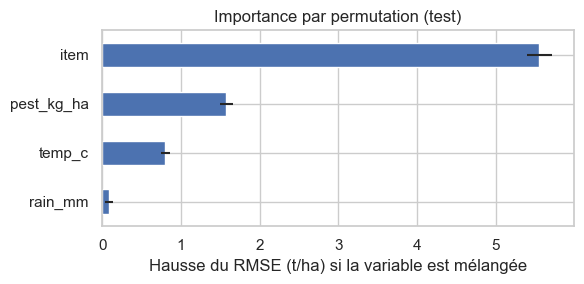

rain_mm       0.090
temp_c        0.802
pest_kg_ha    1.575
item          5.550
dtype: float64

In [11]:
pi = permutation_importance(best_est, test[FEATS], test[TARGET], scoring="neg_root_mean_squared_error",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATS).sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
imp.plot.barh(ax=ax, xerr=pd.Series(pi.importances_std, index=FEATS)[imp.index])
ax.set_xlabel("Hausse du RMSE (t/ha) si la variable est mélangée"); ax.set_title("Importance par permutation (test)")
plt.tight_layout(); fig_imp = fig; plt.show()
imp.round(3)

**À toi** : traduis l'importance des variables pour un agriculteur. Quelle part vient de la **culture** (niveau de rendement) et quelle part du **climat** ? Rappel : `rain_mm` est une moyenne par pays, donc son importance reflète surtout des différences *entre pays*, pas l'effet d'une année pluvieuse.

## 6. Ablation : que perd-on en écartant `area`, `pesticides` et `year` ?

Même modèle (hyperparamètres optimisés), différents jeux de variables, évalués avec **deux types de split** : par pays (réaliste, pays jamais vus) et aléatoire (optimiste, un pays apparaît en train et en test).

In [12]:
set_exp(EXP_ABLATION)
bp = search.best_params_
ABL_SETS = {
    "base (item+pluie+temp)":              BASE,
    "retenu (base + pest. kg/ha)":         FEATS,
    "retenu + year":                       FEATS + ["year"],
    "base + pest. total (t)":              BASE + ["log_pest"],
    "retenu + area":                       FEATS + ["area"],
    "tout (retenu+area+year+pest. total)": FEATS + ["area", "year", "log_pest"],
}
rtr, rte = train_test_split(df, test_size=TEST_SIZE, random_state=SEED)
SPLITS = {"par_pays": (train, test), "aleatoire": (rtr, rte)}

rows = []
for split_name, (a, b) in SPLITS.items():
    for set_name, feats in ABL_SETS.items():
        pipe = make_pipe(best_name, feats).set_params(**bp).fit(a[feats], a[TARGET])
        m = reg_metrics(b[TARGET], pipe.predict(b[feats]), "test")
        with mlflow.start_run(run_name=f"{split_name} | {set_name}"):
            mlflow.set_tags({"stage": "ablation", "mlflow.note.content":
                             "Ablation : apport des variables écartées du modèle final, selon le type de split."})
            mlflow.log_params({"model": best_name, "features": ",".join(feats), "split": split_name, "seed": SEED})
            mlflow.log_metrics(m)
        rows.append({"split": split_name, "variables": set_name, **m})

abl = pd.DataFrame(rows)
abl.pivot(index="variables", columns="split", values="test_r2").loc[list(ABL_SETS)].round(3)

c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packag

split,aleatoire,par_pays
variables,,
base (item+pluie+temp),0.756,0.684
retenu (base + pest. kg/ha),0.770,0.747
retenu + year,0.774,0.752
base + pest. total (t),0.771,0.731
retenu + area,0.772,0.752
tout (retenu+area+year+pest. total),0.784,0.776


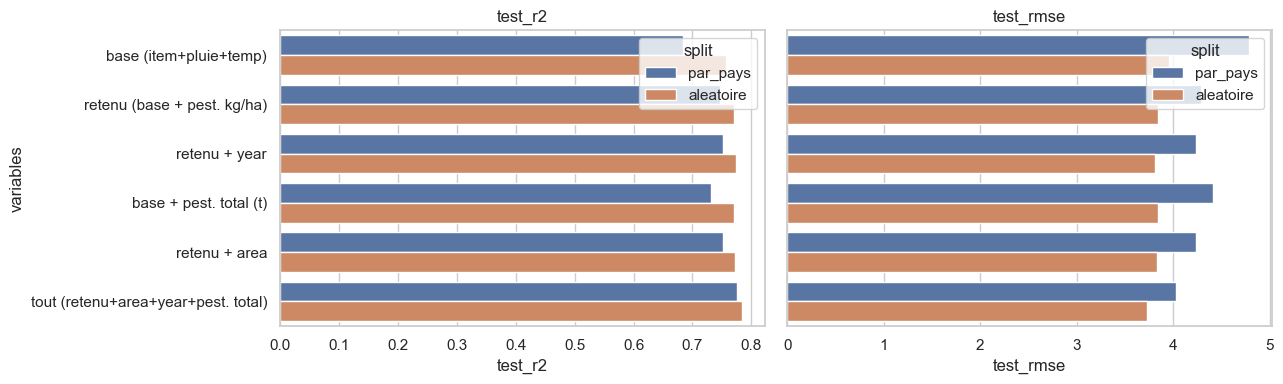

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, metric in zip(axes, ["test_r2", "test_rmse"]):
    sns.barplot(data=abl, y="variables", x=metric, hue="split", ax=ax, order=list(ABL_SETS))
    ax.set_title(metric)
axes[1].set_ylabel("")
plt.tight_layout(); fig_abl = fig; plt.show()

**À toi** : que se passe-t-il quand on ajoute `area` selon le type de split ? Et `pesticides` (variable nationale, pas saisissable par un agriculteur) ? Compare "aleatoire" et "par_pays" : que répondre à "pourquoi avoir écarté ces variables et pourquoi un split par pays" ?

## 7. Modèle final, sauvegarde et démo de recommandation

In [14]:
set_exp(EXP_MODELS)
# Modèle de production : mêmes hyperparamètres, ré-entraîné sur TOUTES les données (le test a déjà servi à l'évaluer)
prod_model = clone(best_est).fit(df[FEATS], df[TARGET])
bundle = {
    "model": prod_model,
    "features": FEATS,
    "items": sorted(df["item"].unique()),
    "item_mean_t_ha": df.groupby("item")[TARGET].mean().to_dict(),   # "norme" de chaque culture
    "model_name": best_name,
    "best_params": {k.replace(p, ""): v for k, v in search.best_params_.items()},
    "sklearn_version": sklearn.__version__,
    "seed": SEED,
    "input_ranges": {c: [float(df[c].min()), float(df[c].max())] for c in FEATS if c != "item"},   # pour borner la saisie dans l'API
}
MODEL_PATH = ROOT / "models" / "yield_model.joblib"
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(bundle, MODEL_PATH)

# Rechargement + contrôle : le modèle sauvegardé donne les mêmes prédictions
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded["model"].predict(df[FEATS].head(50)), prod_model.predict(df[FEATS].head(50)))
print("Modèle sauvegardé :", MODEL_PATH.relative_to(ROOT))

Modèle sauvegardé : models\yield_model.joblib


c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [15]:
with mlflow.start_run(run_name="final_model"):
    mlflow.set_tags({"stage": "final", "mlflow.note.content":
                     f"Modèle final : {best_name} optimisé, ré-entraîné sur toutes les données. Métriques = celles du modèle évalué sur le test (pays jamais vus)."})
    mlflow.log_params({"model": best_name, "features": ",".join(FEATS), "seed": SEED, **bundle["best_params"]})
    mlflow.log_metrics(mt)
    mlflow.log_figure(fig_eval, "eval_pred_vs_real.png")
    mlflow.log_figure(fig_imp, "permutation_importance.png")
    mlflow.log_figure(fig_abl, "ablation.png")
    mlflow.log_table(final[cols].reset_index(), "comparaison_modeles.json")
    mlflow.log_dict(bundle["item_mean_t_ha"], "item_mean_t_ha.json")
    sig = infer_signature(df[FEATS].head(100), prod_model.predict(df[FEATS].head(100)))
    kw = dict(signature=sig, input_example=df[FEATS].head(3), registered_model_name="yield_model")
    try:
        mlflow.sklearn.log_model(prod_model, name="model", **kw)            # MLflow >= 3
    except TypeError:
        mlflow.sklearn.log_model(prod_model, artifact_path="model", **kw)   # MLflow 2.x

c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
2026/10/30 18:06:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
Successfully registered model 'yield_model'.
Created version '1' of model 'yield_model'.


In [19]:
def recommend(bundle, rain_mm, temp_c, pest_kg_ha):
    """Classe toutes les cultures pour des conditions données : rendement prédit et écart vs la norme de la culture."""
    X = pd.DataFrame({"item": bundle["items"], "rain_mm": rain_mm, "temp_c": temp_c, "pest_kg_ha": pest_kg_ha})[bundle["features"]]
    out = pd.DataFrame({"culture": bundle["items"], "rendement_pred_t_ha": bundle["model"].predict(X)})
    out["norme_t_ha"] = out["culture"].map(bundle["item_mean_t_ha"])
    out["ecart_vs_norme_%"] = (out["rendement_pred_t_ha"] / out["norme_t_ha"] - 1) * 100
    return out.sort_values("ecart_vs_norme_%", ascending=False).round(1).reset_index(drop=True)

for rain, temp, pest in [(500, 15, 0.5), (1500, 25, 2.0), (2500, 27, 5.0), (2500, 15, 5.0)]:
    print(f"\n--- Pluie {rain} mm/an, température {temp} °C, pesticides {pest} kg/ha ---")
    print(recommend(bundle, rain, temp, pest).to_string())


--- Pluie 500 mm/an, température 15 °C, pesticides 0.5 kg/ha ---
                culture  rendement_pred_t_ha  norme_t_ha  ecart_vs_norme_%
0           Rice, paddy                  3.4         3.8             -10.1
1        Sweet potatoes                  9.0        10.4             -13.7
2              Potatoes                 15.7        18.3             -14.0
3                  Yams                  8.9        10.4             -14.7
4  Plantains and others                  9.4        11.1             -15.6
5               Sorghum                  1.4         1.8             -21.1
6                 Maize                  2.8         3.7             -24.9
7               Cassava                  7.7        10.3             -25.4
8              Soybeans                  1.2         1.7             -25.9
9                 Wheat                  2.1         3.1             -32.9

--- Pluie 1500 mm/an, température 25 °C, pesticides 2.0 kg/ha ---
                culture  rendement_pred_t_

c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
c:\Users\jacob\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


**À toi** : choisis un scénario ci-dessus et explique le classement à un agriculteur en 3 phrases. Le classement par *écart vs norme* est-il plus utile qu'un classement par t/ha brut (où pommes de terre et manioc gagnent toujours) ?

**Limites à mentionner dans le rapport** : pluie et température sont des moyennes nationales (pas parcellaires) ; `rain_mm` agit comme identifiant de pays ; `pest_kg_ha` est une moyenne nationale estimée par la FAO, corrélée au niveau de développement agricole (corrélation, pas effet causal) ; rendement n'est pas revenu (pas de prix ni de coûts) ; données 1990-2013.